# Quartz / Si two-layer THz-TDS fit with **coarse-grid** $n(f)$, $k(f)$ (6 knots per curve)

Companion to `QuartzSI_dispersive_Adam.ipynb` (polynomial version). Here each layer's $n(f)$ and $k(f)$ are
described by their **values at 6 equally spaced knot frequencies** inside the fit band; between the knots the
curve is interpolated (linear or natural cubic spline, `INTERP`), outside the band it is held at the edge value.

$$
n_j(f) = \sum_{q=1}^{6} A_q(f)\, n_{j,q}, \qquad k_j(f) = \sum_{q=1}^{6} A_q(f)\, k_{j,q},
$$

where $A_q(f)$ are fixed interpolation basis functions (precomputed once as a matrix `A` of shape
`[n_freq, 6]`) and $n_{j,q}$, $k_{j,q}$ are the free parameters. This is still a small model
(2 layers x (6 + 6) + 2 thicknesses = 26 parameters), but unlike a polynomial it makes **no assumption about the
shape** of the dispersion, so it is a good test of whether the polynomial result was an artefact of the basis.

Everything else is unchanged: exact multilayer transfer matrix applied to the measured reference pulse, time-domain
loss (MAE + log-cosh), Adam, two stages (flat -> free knots), soft $k \ge 0$ hinge penalty (`K_POS_WEIGHT`),
loss-landscape scans. The $n(f)$, $k(f)$ plot overlays the polynomial fit (if `QuartzSi_poly_coefs.npz` from the
other notebook is in the same folder) and literature values.

In [24]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:90% !important; }</style>"))

In [25]:
# Interactive figures need the `ipympl` package; otherwise VS Code / Jupyter render inline.
try:
    import ipympl  # noqa
    %matplotlib widget
except ImportError:
    %matplotlib inline

In [26]:
from tqdm.auto import tqdm

import numpy as np
from scipy.interpolate import CubicSpline
import matplotlib.pyplot as plt
import torch

from Simulate import RTm_batched, simulate_from_signal
from data_quartzsi import t_r_raw as t_r, A_r, A_s

torch.set_default_dtype(torch.float32)
c_light = 299792458.0

## 1. Data (or synthetic dispersive test case)

In [27]:
simulate_data = False      # True -> build a synthetic sample with KNOWN n(f), k(f) to test recovery

In [28]:
# Global variables shared by everything below
L = len(A_r)                      # 2425 points
deltat = (t_r[1] - t_r[0]) * 1e-12
t_r = t_r - t_r[0]

x_exp = np.asarray(A_r, dtype=np.float32)          # reference pulse
true_x_exp = np.asarray(A_s, dtype=np.float32)     # sample pulse (overwritten if simulate_data)

# FFT grid used by the forward model (same convention as Simulate.simulate_parallel: M = 2L, N = 4L)
M = 2 * L
N = 4 * L
deltaf = 1.0 / (N * deltat)
dk = 2 * np.pi * deltaf / c_light
k_vals = torch.arange(M + 1, dtype=torch.float32)          # frequency index
f_THz = (k_vals * deltaf / 1e12)                           # frequency axis of T(f), THz
f_np = f_THz.numpy()

print(f"L = {L}, dt = {deltat*1e15:.1f} fs, df = {deltaf/1e9:.2f} GHz, f_max(T grid) = {f_np[-1]:.1f} THz")

L = 2425, dt = 33.0 fs, df = 3.12 GHz, f_max(T grid) = 15.2 THz


## 2. Coarse frequency grid (knots) and the dispersive forward model

In [29]:
# ---- knot grid ---------------------------------------------------------------------
F_LO, F_HI = 0.2, 3.0    # THz : band where the data carries information (checked against the spectrum below)
N_KNOTS    = 6           # knots per curve (n and k of each layer)
INTERP     = 'cubic'     # 'linear' or 'cubic' (natural cubic spline through the knots)

f_knots = np.linspace(F_LO, F_HI, N_KNOTS)               # THz
print("knot frequencies (THz):", np.round(f_knots, 3))

def interp_basis(f, f_knots=f_knots, kind=INTERP):
    '''
    Interpolation basis matrix A (shape [len(f), N_KNOTS]) such that  curve(f) = A @ values_at_knots.
    Built by interpolating the unit vectors, so any interpolation scheme that is linear in the knot values works.
    Frequencies outside [F_LO, F_HI] are clipped -> the curve is held at its edge value there.
    '''
    f = np.clip(np.asarray(f, dtype=np.float64), f_knots[0], f_knots[-1])
    A = np.zeros((len(f), len(f_knots)))
    for q in range(len(f_knots)):
        e = np.zeros(len(f_knots)); e[q] = 1.0
        if kind == 'linear':
            A[:, q] = np.interp(f, f_knots, e)
        elif kind == 'cubic':
            A[:, q] = CubicSpline(f_knots, e, bc_type='natural')(f)
        else:
            raise ValueError(kind)
    return A

A_grid = torch.as_tensor(interp_basis(f_np), dtype=torch.float32)    # [M+1, N_KNOTS] basis on the T-frequency grid

def curve_from_knots(values, A=A_grid):
    '''values: tensor [..., N_KNOTS] -> curve on the frequency grid of A: [..., len(f)].'''
    return values @ A.T

knot frequencies (THz): [0.2  0.76 1.32 1.88 2.44 3.  ]


In [30]:
# ---- per-frequency transfer function / time-domain pulse -----------------------------
def simulate_dispersive(x, layers, deltat):
    '''
    Same algorithm as Simulate.simulate_parallel, but each layer is (n_complex, d) where n_complex may be
    a torch tensor of shape [M+1] (one complex index per frequency of the T grid) or a scalar.

    Returns (T [N] complex, y [N] real).  y[:L] is the simulated sample pulse.
    '''
    xt = torch.as_tensor(x, dtype=torch.float32)
    device = xt.device
    n0 = torch.tensor(1.0, dtype=torch.cfloat, device=device)

    batched_layers = []
    for nj, d in layers:
        nj = torch.as_tensor(nj, dtype=torch.cfloat, device=device)
        if nj.ndim == 0:
            nj = nj.expand(M + 1)
        kD = dk * k_vals * d                                # [M+1], real (d may carry a gradient)
        batched_layers.append((nj, kD))

    _, T_half = RTm_batched(len(batched_layers), n0, batched_layers)

    T = torch.zeros(N, dtype=torch.cfloat, device=device)
    T[:M + 1] = T_half
    T[M + 1:] = torch.conj(torch.flip(T[1:M], dims=[0]))    # Hermitian symmetry for a real pulse

    z = torch.zeros(N, dtype=torch.float32, device=device)
    z[:L] = xt
    X = torch.fft.fft(z) / N
    y = N * torch.fft.ifft(T * X).real
    return T, y

In [31]:
# Consistency check: with flat (scalar) indices the new simulator must reproduce Simulate.simulate_from_signal
layers_flat = [(1.982 - 0.0071j, 1e-3), (3.4 - 0.0054j, 0.4e-3)]
_, y_old = simulate_from_signal(x_exp, layers_flat, deltat)
_, y_new = simulate_dispersive(x_exp, [(torch.tensor(n), torch.tensor(d)) for n, d in layers_flat], deltat)
print("max |y_new - y_old| =", (y_new - y_old).abs().max().item(), " (should be ~1e-7)")

max |y_new - y_old| = 0.0  (should be ~1e-7)


In [32]:
if simulate_data:
    # Synthetic sample with a KNOWN dispersion (given at the knots), to verify the fit recovers it.
    true_coefs = {
        'n1': [1.955, 1.962, 1.966, 1.968, 1.971, 1.976],  'k1': [0.000, 0.003, 0.006, 0.009, 0.012, 0.014],
        'n2': [3.4175] * 6,                                 'k2': [0.0] * 6,
        'd':  [0.980e-3, 0.400e-3],
    }
    layers_true = []
    for j in (1, 2):
        n = curve_from_knots(torch.tensor(true_coefs[f'n{j}']))
        k = curve_from_knots(torch.tensor(true_coefs[f'k{j}']))
        layers_true.append((n - 1j * k, torch.tensor(true_coefs['d'][j - 1])))
    _, y_true = simulate_dispersive(x_exp, layers_true, deltat)
    rng = np.random.default_rng(0)
    true_x_exp = (y_true[:L].numpy() + 0.002 * rng.standard_normal(L)).astype(np.float32)
else:
    true_coefs = None

## 3. Where is the signal? (choose $f_{lo}$, $f_{hi}$)

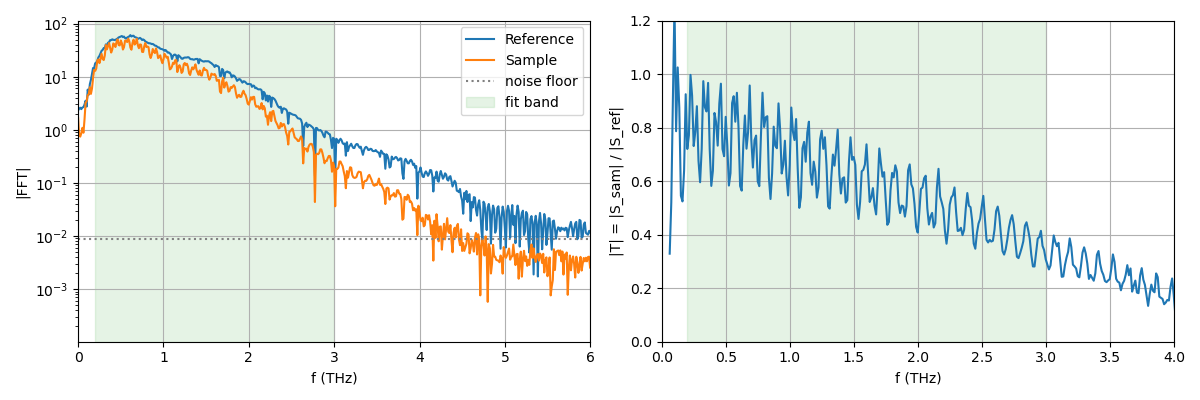

In [33]:
f_data = np.fft.rfftfreq(L, deltat) / 1e12
S_ref = np.abs(np.fft.rfft(x_exp))
S_sam = np.abs(np.fft.rfft(true_x_exp))
noise_floor = np.median(S_ref[f_data > 6.0])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogy(f_data, S_ref, label='Reference')
ax[0].semilogy(f_data, S_sam, label='Sample')
ax[0].axhline(noise_floor, color='gray', ls=':', label='noise floor')
ax[0].axvspan(F_LO, F_HI, color='C2', alpha=0.12, label='fit band')
ax[0].set_xlim(0, 6); ax[0].set_xlabel('f (THz)'); ax[0].set_ylabel('|FFT|'); ax[0].legend(); ax[0].grid()

ok = (f_data > 0.05)
ax[1].plot(f_data[ok], (S_sam / S_ref)[ok])
ax[1].axvspan(F_LO, F_HI, color='C2', alpha=0.12)
ax[1].set_xlim(0, 4); ax[1].set_ylim(0, 1.2); ax[1].set_xlabel('f (THz)'); ax[1].set_ylabel('|T| = |S_sam| / |S_ref|'); ax[1].grid()
plt.tight_layout(); plt.show()

## 4. Parametrised two-layer model (knot values as parameters)

Each knot value is written as `init + raw * scale` with the trainable `raw` starting at 0, as in the polynomial
notebook. Stage 1 ties all knots of a curve together (one common offset per curve -> flat $n$, $k$: the original
6-parameter problem); stage 2 frees every knot individually.

In [34]:
class DispersiveTwoLayerGrid:
    def __init__(self, n_init, k_init, d_init,
                 n_scale=0.05,        # absolute step scale for n knots   (Adam moves ~ lr * scale per iteration)
                 k_scale=0.005,       # absolute step scale for k knots
                 d_scale=None):
        self.n_init = torch.tensor([[n_init[j]] * N_KNOTS for j in range(2)])      # [2, N_KNOTS]
        self.k_init = torch.tensor([[k_init[j]] * N_KNOTS for j in range(2)])
        self.d_init = torch.tensor(list(d_init), dtype=torch.float32)

        self.n_scale = torch.full((2, N_KNOTS), float(n_scale))
        self.k_scale = torch.full((2, N_KNOTS), float(k_scale))
        self.d_scale = self.d_init.clone() if d_scale is None else torch.tensor(d_scale, dtype=torch.float32)

        # trainable: one common offset per curve (stage 1) + individual knot offsets (stage 2)
        self.n_off = torch.zeros(2, requires_grad=True)
        self.k_off = torch.zeros(2, requires_grad=True)
        self.n_raw = torch.zeros(2, N_KNOTS, requires_grad=True)
        self.k_raw = torch.zeros(2, N_KNOTS, requires_grad=True)
        self.d_raw = torch.zeros(2, requires_grad=True)

        self.knots_free = 0.0          # 0 -> knots tied (flat curves), 1 -> every knot free
        self.k_free = 1.0
        self.d_mask = torch.ones(2)
        self.band = (f_THz >= F_LO) & (f_THz <= F_HI)

    # ---- configuration helpers ---------------------------------------------------
    def parameters(self):
        return [self.n_off, self.k_off, self.n_raw, self.k_raw, self.d_raw]

    def set_dispersion(self, free: bool):
        '''True: every knot is free (dispersive). False: knots tied -> flat n, k (only the common offsets move).'''
        self.knots_free = 1.0 if free else 0.0

    def set_thickness(self, free: bool):
        self.d_mask[:] = 1.0 if free else 0.0

    def set_absorption(self, free: bool):
        self.k_free = 1.0 if free else 0.0

    # ---- physical quantities -------------------------------------------------------
    def n_knots(self):
        return self.n_init + self.n_scale * (self.n_off[:, None] + self.knots_free * self.n_raw)          # [2, N_KNOTS]
    def k_knots(self):
        return self.k_init + self.k_free * self.k_scale * (self.k_off[:, None] + self.knots_free * self.k_raw)
    def d(self):
        return self.d_init + self.d_raw * self.d_scale * self.d_mask                                       # [2]

    def nk(self, f=None):
        '''n(f), k(f) for both layers on the T-grid (f=None) or on a user-supplied frequency axis (THz).'''
        A = A_grid if f is None else torch.as_tensor(interp_basis(np.asarray(f)), dtype=torch.float32)
        return curve_from_knots(self.n_knots(), A), curve_from_knots(self.k_knots(), A)

    def layers(self):
        n, k = self.nk(); d = self.d()
        return [(n[j] - 1j * k[j], d[j]) for j in range(2)]

    def forward(self, x):
        T, y = simulate_dispersive(x, self.layers(), deltat)
        return T, y[:L]

    def k_negativity(self):
        '''Mean of max(0, -k(f)) over the fit band and both layers: the quantity penalised in the loss.'''
        _, k = self.nk()
        return torch.relu(-k[:, self.band]).mean()

    def k_negative_fraction(self):
        with torch.no_grad():
            _, k = self.nk()
            return (k[:, self.band] < 0).float().mean(dim=1).numpy()

    # ---- bookkeeping ----------------------------------------------------------------
    def state(self):
        with torch.no_grad():
            return dict(n=self.n_knots().clone(), k=self.k_knots().clone(), d=self.d().clone())

    def load_state(self, st):
        '''Make the current knot values the new init (raw -> 0). Used between stages.'''
        with torch.no_grad():
            self.n_init = st['n'].clone(); self.k_init = st['k'].clone(); self.d_init = st['d'].clone()
            self.n_off.zero_(); self.k_off.zero_(); self.n_raw.zero_(); self.k_raw.zero_(); self.d_raw.zero_()
            self.d_scale = self.d_init.clone()

    def report(self, coefs_true=None):
        st = self.state()
        print("knots (THz):      " + '  '.join(f"{f:7.3f}" for f in f_knots))
        for j in range(2):
            n = '  '.join(f"{v:7.4f}" for v in st['n'][j].tolist())
            k = '  '.join(f"{v:7.4f}" for v in st['k'][j].tolist())
            print(f"layer {j+1} n knots:  {n}")
            print(f"layer {j+1} k knots:  {k}      d = {st['d'][j].item()*1e6:8.2f} um")
        neg = self.k_negative_fraction()
        print(f"fraction of band with k<0: layer1 {neg[0]*100:.1f} %, layer2 {neg[1]*100:.1f} %")
        if coefs_true is not None:
            print("true:", coefs_true)

## 5. Loss and optimizer loop

In [35]:
def mae_loss(y_test, y_pred):
    return np.mean(np.abs(y_test - y_pred))

def log_cosh_loss(y_pred, y_test):
    diff = y_pred - y_test
    return torch.mean(torch.log(torch.cosh(diff + 1e-12)))

def data_loss(y_pred, y_test):
    # identical to the original notebook: MAE + log-cosh
    return (y_test - y_pred).abs().mean() + log_cosh_loss(y_pred, y_test)

K_POS_WEIGHT = 1.0     # lambda_k : weight of the soft k>=0 penalty. 0 -> no penalty at all.

def total_loss(y_pred, y_test, model=None):
    '''data loss + soft positivity nudge on k(f).
    The penalty is a hinge: K_POS_WEIGHT * mean over the band of max(0, -k). It is exactly zero while k >= 0
    everywhere (so a positive solution is untouched) and grows linearly with the depth of a negative excursion,
    i.e. it pushes back with a constant force K_POS_WEIGHT instead of forbidding k<0. With k ~ 1e-2 and a data loss
    ~ 3e-3, K_POS_WEIGHT = 1 makes a -1e-3 dip over half the band cost ~5e-4, a visible but not dominant nudge.'''
    loss = data_loss(y_pred, y_test)
    if model is not None and K_POS_WEIGHT > 0:
        loss = loss + K_POS_WEIGHT * model.k_negativity()
    return loss

In [36]:
def fit(model, n_iters=20000, lr=1e-4, print_step=2000, label=''):
    '''
    Adam on the raw parameters of `model`. Returns a trajectory dict with per-iteration histories:
      traj['n']  [iters, 2, N_KNOTS]   n knot values for both layers
      traj['k']  [iters, 2, N_KNOTS]   k knot values for both layers
      traj['penalty'] [iters]    K_POS_WEIGHT * <max(0,-k)> part of the loss
      traj['d']  [iters, 2]
      traj['loss'] [iters]
    '''
    y_meas = torch.as_tensor(true_x_exp, dtype=torch.float32)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    hist = {'n': [], 'k': [], 'd': [], 'loss': [], 'penalty': []}

    def record(loss):
        st = model.state()
        hist['n'].append(st['n'].numpy()); hist['k'].append(st['k'].numpy())
        hist['d'].append(st['d'].numpy()); hist['loss'].append(loss.item())
        with torch.no_grad():
            hist['penalty'].append(K_POS_WEIGHT * model.k_negativity().item())

    _, y = model.forward(x_exp)
    loss = total_loss(y, y_meas, model)
    record(loss)
    print(f"[{label}] Epoch={1:6d}  loss={loss.item():.4e}")

    for i in tqdm(range(1, n_iters), desc=f'fit {label}', leave=False):
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        _, y = model.forward(x_exp)
        loss = total_loss(y, y_meas, model)

        with torch.no_grad():
            record(loss)
            if i == n_iters - 1 or (i + 1) % print_step == 0:
                st = model.state()
                print(f"[{label}] Epoch={i+1:6d}  loss={loss.item():.4e} (k-penalty {hist['penalty'][-1]:.1e})  "
                      f"n1(1THz)={st['n'][0,0]:.5f} k1={st['k'][0,0]:.5f} d1={st['d'][0]*1e6:.1f}um  "
                      f"n2(1THz)={st['n'][1,0]:.5f} k2={st['k'][1,0]:.5f} d2={st['d'][1]*1e6:.1f}um")

    return {key: np.array(v) for key, v in hist.items()}

## 6. Plot helpers

In [37]:
def plot_loss(trajs, labels):
    plt.figure(figsize=(10, 3.5))
    off = 0
    for traj, lab in zip(trajs, labels):
        plt.plot(np.arange(off, off + len(traj['loss'])), traj['loss'], label=lab)
        off += len(traj['loss'])
    off = 0
    for traj, lab in zip(trajs, labels):
        if np.any(traj['penalty'] > 0):
            plt.plot(np.arange(off, off + len(traj['penalty'])), traj['penalty'], ls=':', label=f'{lab}: k-penalty part')
        off += len(traj['loss'])
    plt.yscale('log'); plt.xlabel('Iteration'); plt.ylabel('Loss'); plt.legend(); plt.grid(); plt.title('Optimization')
    plt.show()


def plot_pulses(model, title='Sample pulse: experiment vs dispersive model'):
    with torch.no_grad():
        _, y = model.forward(x_exp)
    y = y.numpy()
    print(f"MAE = {mae_loss(true_x_exp, y):.4e}")
    fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
    ax[0].plot(t_r, true_x_exp, label='Sample Pulse (Experimental)', color='C1')
    ax[0].plot(t_r, y, label='Sample Pulse (Simulated, n(f), k(f))', color='black', alpha=0.75, ls='--')
    ax[0].set_title(title); ax[0].legend(); ax[0].grid()
    ax[1].plot(t_r, true_x_exp - y, color='C3', lw=0.8); ax[1].set_ylabel('residual'); ax[1].set_xlabel('t (ps)'); ax[1].grid()
    plt.tight_layout(); plt.show()


LITERATURE = {
    # reference values for overlay; extend / correct as needed
    'Si (HR float-zone, Dai et al. 2004)': {'layer': 1, 'n': 3.4175, 'k': None},
    # 'fused silica (Naftaly & Miles 2007)': {'layer': 0, 'n': 1.95, 'k': None},   # TODO: fill in what applies to layer 1
}

def plot_nk(models, labels, f_plot=np.linspace(0.05, 4.0, 400), true_coefs=None, poly_npz=None, literature=LITERATURE):
    '''n(f) and k(f) of both layers for one or several fitted models; knots marked; the fit band is shaded.
    poly_npz: path to QuartzSi_poly_coefs.npz from the polynomial notebook -> overlaid as dashed curves.'''
    fig, ax = plt.subplots(2, 2, figsize=(12, 7))
    for m, lab in zip(models, labels):
        with torch.no_grad():
            n, k = m.nk(f_plot); st = m.state()
        for j in range(2):
            ln, = ax[0, j].plot(f_plot, n[j].numpy(), label=lab)
            ax[0, j].plot(f_knots, st['n'][j].numpy(), 'o', color=ln.get_color(), ms=4)
            lk, = ax[1, j].plot(f_plot, k[j].numpy(), label=lab)
            ax[1, j].plot(f_knots, st['k'][j].numpy(), 'o', color=lk.get_color(), ms=4)
    if true_coefs is not None:
        At = interp_basis(f_plot)
        for j in range(2):
            ax[0, j].plot(f_plot, At @ np.array(true_coefs[f'n{j+1}']), 'k:', label='true')
            ax[1, j].plot(f_plot, At @ np.array(true_coefs[f'k{j+1}']), 'k:', label='true')
    if poly_npz is not None:
        try:
            P = np.load(poly_npz)
            xp = (np.clip(f_plot, float(P['F_LO']), float(P['F_HI'])) - float(P['F_REF'])) / float(P['F_SCALE'])
            for j in range(2):
                ax[0, j].plot(f_plot, np.polyval(P['n_coefs'][j][::-1], xp), '--', color='gray', label='polynomial fit')
                ax[1, j].plot(f_plot, np.polyval(P['k_coefs'][j][::-1], xp), '--', color='gray', label='polynomial fit')
        except FileNotFoundError:
            print(f"(no {poly_npz} found - run the polynomial notebook first to overlay it)")
    for name, ref in literature.items():
        j = ref['layer']
        if ref.get('n') is not None: ax[0, j].axhline(ref['n'], color='C3', ls='-.', lw=1, label=name)
        if ref.get('k') is not None: ax[1, j].axhline(ref['k'], color='C3', ls='-.', lw=1, label=name)
    for j, name in enumerate(['layer 1 (quartz)', 'layer 2 (Si)']):
        for i, q in enumerate(['n', 'k']):
            a = ax[i, j]
            a.axvspan(F_LO, F_HI, color='C2', alpha=0.10)
            a.set_xlabel('f (THz)'); a.set_ylabel(f'{q}(f)'); a.grid(); a.legend(fontsize=8)
            if q == 'k': a.axhline(0, color='k', lw=0.6)
        ax[0, j].set_title(name)
    plt.tight_layout(); plt.show()


def plot_spectral_residual(models, labels):
    '''|FFT| of the residual: tells you in which band the model still disagrees with the data.'''
    plt.figure(figsize=(10, 3.5))
    plt.semilogy(f_data, S_sam, color='gray', alpha=0.5, label='|sample spectrum|')
    for m, lab in zip(models, labels):
        with torch.no_grad():
            _, y = m.forward(x_exp)
        plt.semilogy(f_data, np.abs(np.fft.rfft(true_x_exp - y.numpy())), label=f'|residual| {lab}')
    plt.axvspan(F_LO, F_HI, color='C2', alpha=0.10)
    plt.xlim(0, 5); plt.xlabel('f (THz)'); plt.legend(); plt.grid(); plt.show()


def plot_coef_history(traj, title=''):
    fig, ax = plt.subplots(2, 2, figsize=(12, 6))
    for j in range(2):
        for q in range(N_KNOTS):
            ax[0, j].plot(traj['n'][:, j, q] - traj['n'][0, j, q], label=f'n @ {f_knots[q]:.2f} THz')
            ax[1, j].plot(traj['k'][:, j, q] - traj['k'][0, j, q], label=f'k @ {f_knots[q]:.2f} THz')
        ax[0, j].set_title(f'layer {j+1} {title}'); ax[0, j].legend(fontsize=7); ax[0, j].grid()
        ax[1, j].legend(fontsize=7); ax[1, j].grid(); ax[1, j].set_xlabel('iteration')
    plt.tight_layout(); plt.show()

## 7. Stage 1 — flat fit ($c_0$ and $d$ only)

Reproduces the original 6-parameter problem. Its solution is the starting point for the dispersive stage.

In [38]:
n_init = [1.9820, 3.4000]
k_init = [0.0071, 0.0054]
d_init = [  1e-3, 0.4e-3]

FIT_THICKNESS = True
N_ITERS_FLAT = 15000
N_ITERS_DISP = 30000
LR = 1e-4

[flat] Epoch=     1  loss=4.6598e-02


fit flat:   0%|          | 0/14999 [00:00<?, ?it/s]

[flat] Epoch=  2500  loss=5.6377e-03 (k-penalty 0.0e+00)  n1(1THz)=1.97937 k1=0.00591 d1=986.2um  n2(1THz)=3.39765 k2=0.00423 d2=386.7um
[flat] Epoch=  5000  loss=4.8734e-03 (k-penalty 0.0e+00)  n1(1THz)=1.97665 k1=0.00479 d1=987.9um  n2(1THz)=3.39700 k2=0.00308 d2=387.0um
[flat] Epoch=  7500  loss=4.6498e-03 (k-penalty 0.0e+00)  n1(1THz)=1.97428 k1=0.00419 d1=989.1um  n2(1THz)=3.39958 k2=0.00223 d2=386.8um
[flat] Epoch= 10000  loss=4.5933e-03 (k-penalty 0.0e+00)  n1(1THz)=1.97308 k1=0.00424 d1=989.7um  n2(1THz)=3.40576 k2=0.00142 d2=386.1um
[flat] Epoch= 12500  loss=4.5416e-03 (k-penalty 0.0e+00)  n1(1THz)=1.97210 k1=0.00464 d1=990.3um  n2(1THz)=3.40981 k2=0.00034 d2=385.6um
[flat] Epoch= 15000  loss=4.5230e-03 (k-penalty 0.0e+00)  n1(1THz)=1.97116 k1=0.00478 d1=990.7um  n2(1THz)=3.41376 k2=0.00000 d2=385.2um
knots (THz):        0.200    0.760    1.320    1.880    2.440    3.000
layer 1 n knots:   1.9712   1.9712   1.9712   1.9712   1.9712   1.9712
layer 1 k knots:   0.0048   0.0048  

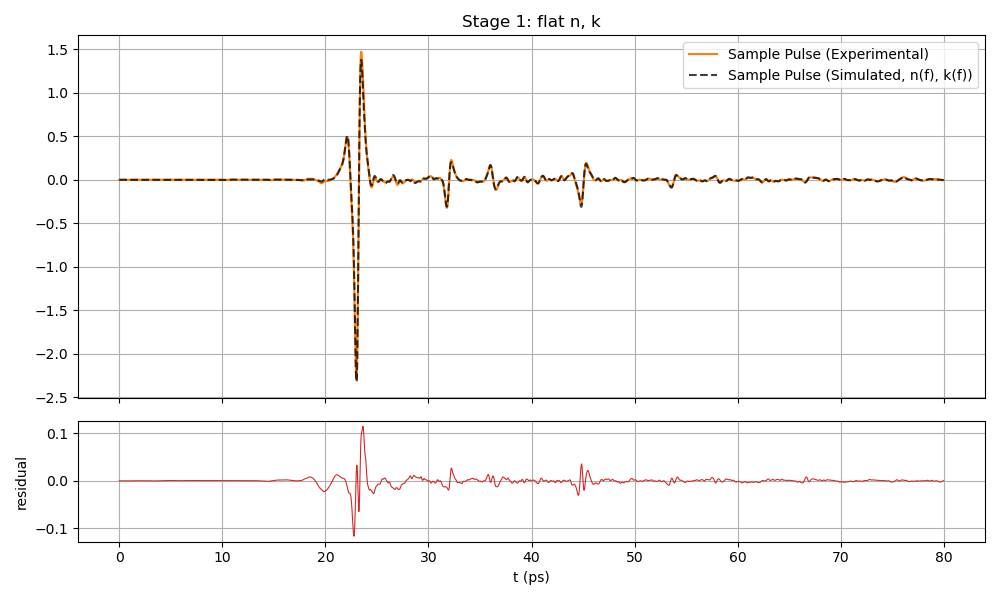

In [39]:
model = DispersiveTwoLayerGrid(n_init, k_init, d_init)
model.set_dispersion(False)          # knots tied -> flat n, k
model.set_thickness(FIT_THICKNESS)

traj_flat = fit(model, n_iters=N_ITERS_FLAT, lr=LR, print_step=2500, label='flat')
model.report()
plot_pulses(model, title='Stage 1: flat n, k')

## 8. Stage 2 — free every knot

Starts from the stage-1 solution. The flat model is kept as `model_flat` for comparison.

In [40]:
import copy
model_flat = copy.deepcopy(model)     # frozen snapshot of the flat solution

model.load_state(model.state())       # make the stage-1 result the new 'init' (raw -> 0, fresh Adam moments)
model.set_dispersion(True)
model.set_thickness(FIT_THICKNESS)

traj_disp = fit(model, n_iters=N_ITERS_DISP, lr=LR, print_step=5000, label='dispersive')
model.report(true_coefs)

[dispersive] Epoch=     1  loss=4.5230e-03


fit dispersive:   0%|          | 0/29999 [00:00<?, ?it/s]

[dispersive] Epoch=  5000  loss=3.0184e-03 (k-penalty 2.6e-07)  n1(1THz)=1.96491 k1=0.00192 d1=991.8um  n2(1THz)=3.41380 k2=0.00001 d2=384.3um
[dispersive] Epoch= 10000  loss=2.8714e-03 (k-penalty 7.1e-07)  n1(1THz)=1.96289 k1=-0.00022 d1=992.2um  n2(1THz)=3.41764 k2=-0.00000 d2=384.0um
[dispersive] Epoch= 15000  loss=2.8624e-03 (k-penalty 2.1e-06)  n1(1THz)=1.96234 k1=-0.00039 d1=992.5um  n2(1THz)=3.41909 k2=0.00000 d2=383.8um
[dispersive] Epoch= 20000  loss=2.8585e-03 (k-penalty 1.9e-06)  n1(1THz)=1.96205 k1=-0.00038 d1=992.6um  n2(1THz)=3.42021 k2=0.00000 d2=383.7um
[dispersive] Epoch= 25000  loss=2.8551e-03 (k-penalty 1.9e-06)  n1(1THz)=1.96192 k1=-0.00038 d1=992.8um  n2(1THz)=3.42090 k2=0.00000 d2=383.6um
[dispersive] Epoch= 30000  loss=2.8544e-03 (k-penalty 1.9e-06)  n1(1THz)=1.96175 k1=-0.00037 d1=992.8um  n2(1THz)=3.42168 k2=0.00000 d2=383.5um
knots (THz):        0.200    0.760    1.320    1.880    2.440    3.000
layer 1 n knots:   1.9617   1.9675   1.9690   1.9699   1.9695   1

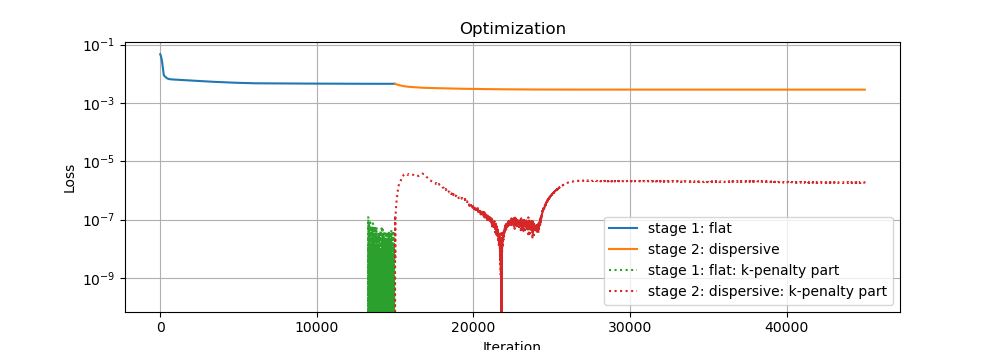

MAE = 2.8366e-03


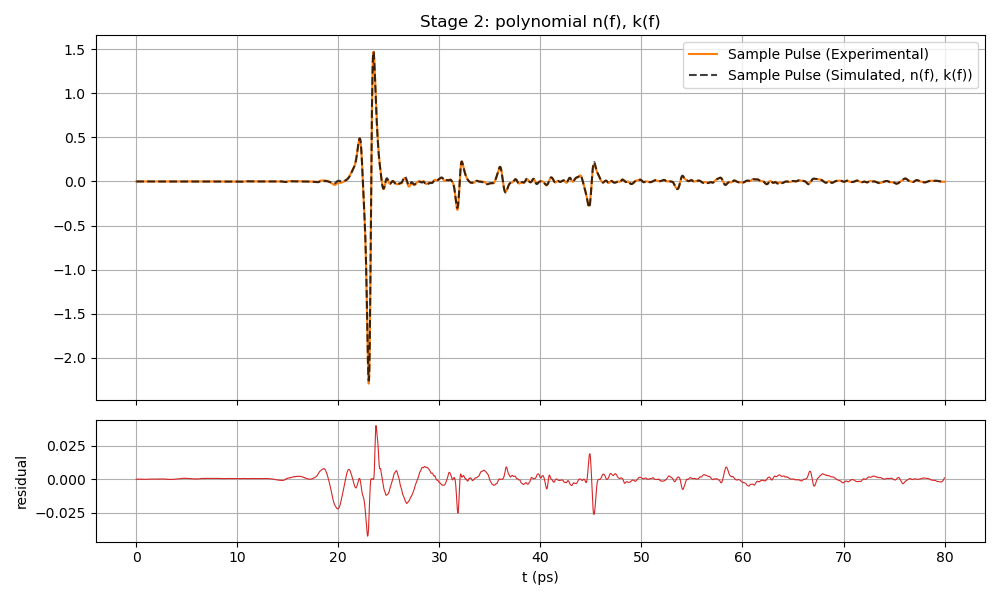

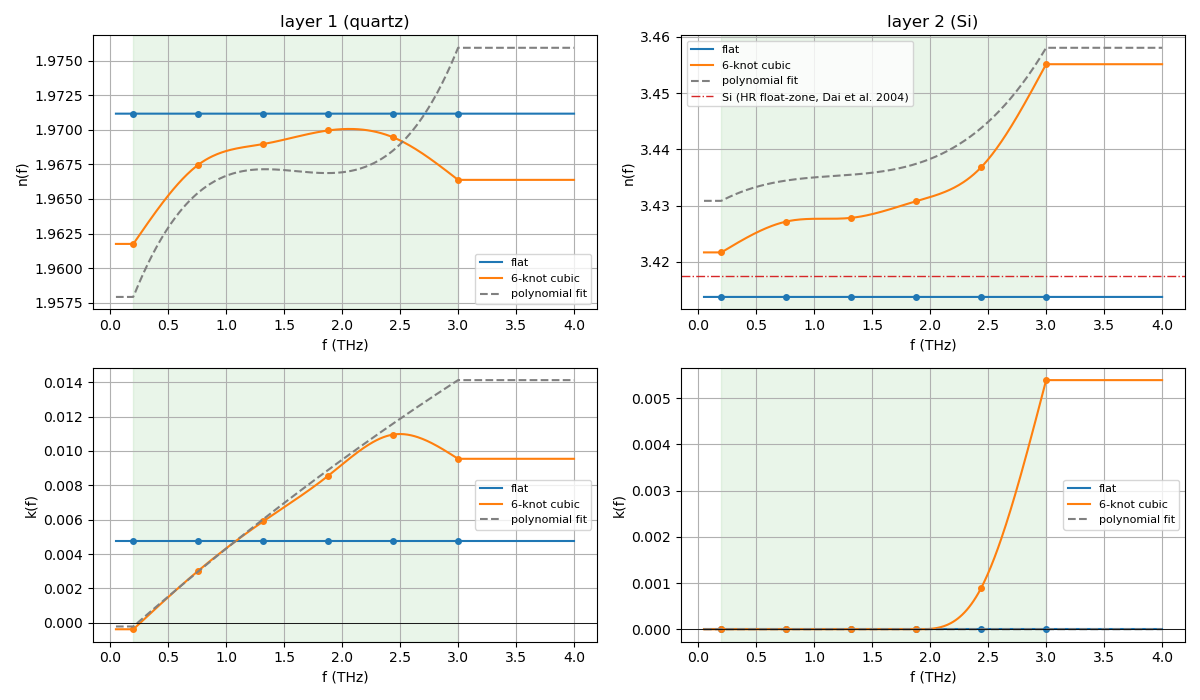

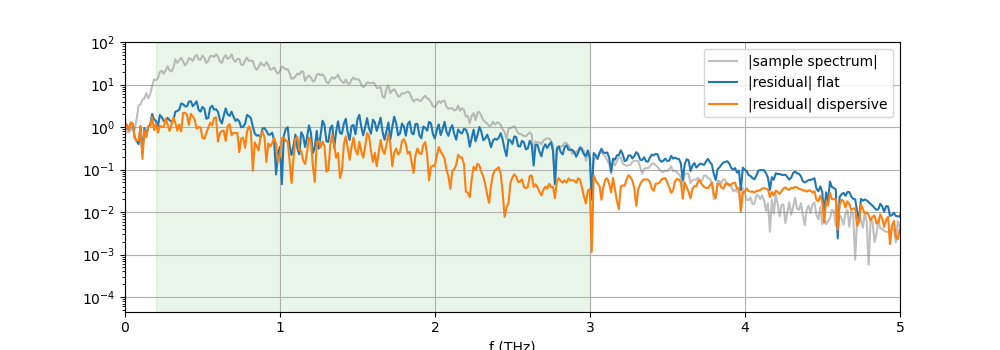

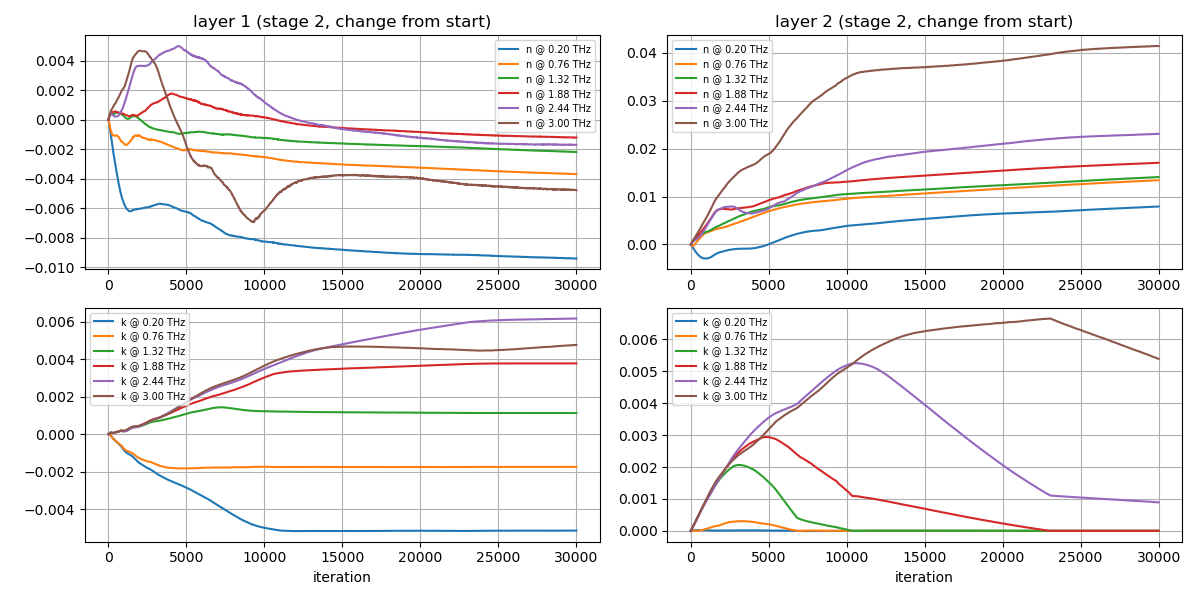

In [41]:
plot_loss([traj_flat, traj_disp], ['stage 1: flat', 'stage 2: dispersive'])
plot_pulses(model, title='Stage 2: polynomial n(f), k(f)')
plot_nk([model_flat, model], ['flat', f'{N_KNOTS}-knot {INTERP}'], true_coefs=true_coefs, poly_npz='QuartzSi_poly_coefs.npz')
plot_spectral_residual([model_flat, model], ['flat', 'dispersive'])
plot_coef_history(traj_disp, '(stage 2, change from start)')

## 8b. Robustness: pin the silicon thickness (or index) and refit the knots

The $n$-$d$ valley means the data fix $n_{\rm Si}\,d_{\rm Si}$ to ~0.1 % but not the two separately. This cell
restarts stage 2 from the same stage-1 snapshot with $d_2$ pinned to a chosen value (default: the thickness implied by
the literature index, $n_{\rm Si}=3.4175$; replace by a mechanically measured thickness when available) and compares
the resulting $n(f)$, $k(f)$ with the free-thickness solution. If the two agree except for a rigid shift of $n_{\rm Si}$,
the shape of the dispersion is robust and only the absolute level of $n_{\rm Si}$ is degenerate with $d_2$.

pinning d2 = 384.65 um
[d2 pinned] Epoch=     1  loss=4.7330e-03


fit d2 pinned:   0%|          | 0/29999 [00:00<?, ?it/s]

[d2 pinned] Epoch=  5000  loss=3.0228e-03 (k-penalty 3.0e-07)  n1(1THz)=1.96548 k1=0.00190 d1=991.5um  n2(1THz)=3.41083 k2=0.00001 d2=384.7um
[d2 pinned] Epoch= 10000  loss=2.8792e-03 (k-penalty 8.5e-07)  n1(1THz)=1.96427 k1=-0.00024 d1=991.6um  n2(1THz)=3.41106 k2=-0.00000 d2=384.7um
[d2 pinned] Epoch= 15000  loss=2.8689e-03 (k-penalty 2.8e-06)  n1(1THz)=1.96401 k1=-0.00045 d1=991.7um  n2(1THz)=3.41138 k2=0.00000 d2=384.7um
[d2 pinned] Epoch= 20000  loss=2.8666e-03 (k-penalty 3.0e-06)  n1(1THz)=1.96393 k1=-0.00047 d1=991.7um  n2(1THz)=3.41151 k2=0.00000 d2=384.7um
[d2 pinned] Epoch= 25000  loss=2.8653e-03 (k-penalty 3.1e-06)  n1(1THz)=1.96402 k1=-0.00048 d1=991.7um  n2(1THz)=3.41138 k2=0.00000 d2=384.7um
[d2 pinned] Epoch= 30000  loss=2.8648e-03 (k-penalty 2.8e-06)  n1(1THz)=1.96401 k1=-0.00046 d1=991.7um  n2(1THz)=3.41144 k2=0.00000 d2=384.7um
knots (THz):        0.200    0.760    1.320    1.880    2.440    3.000
layer 1 n knots:   1.9640   1.9699   1.9712   1.9718   1.9711   1.9696


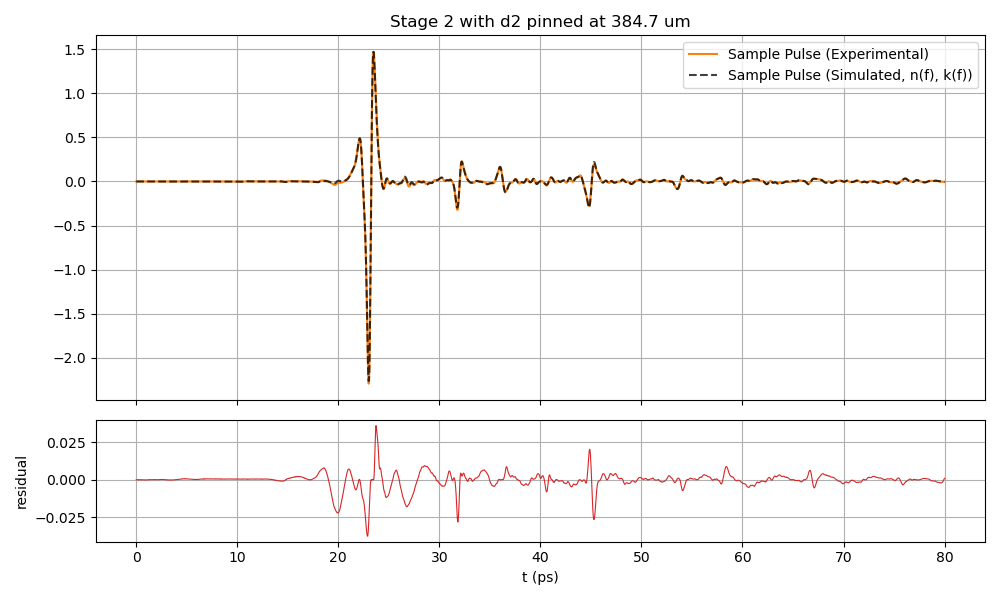

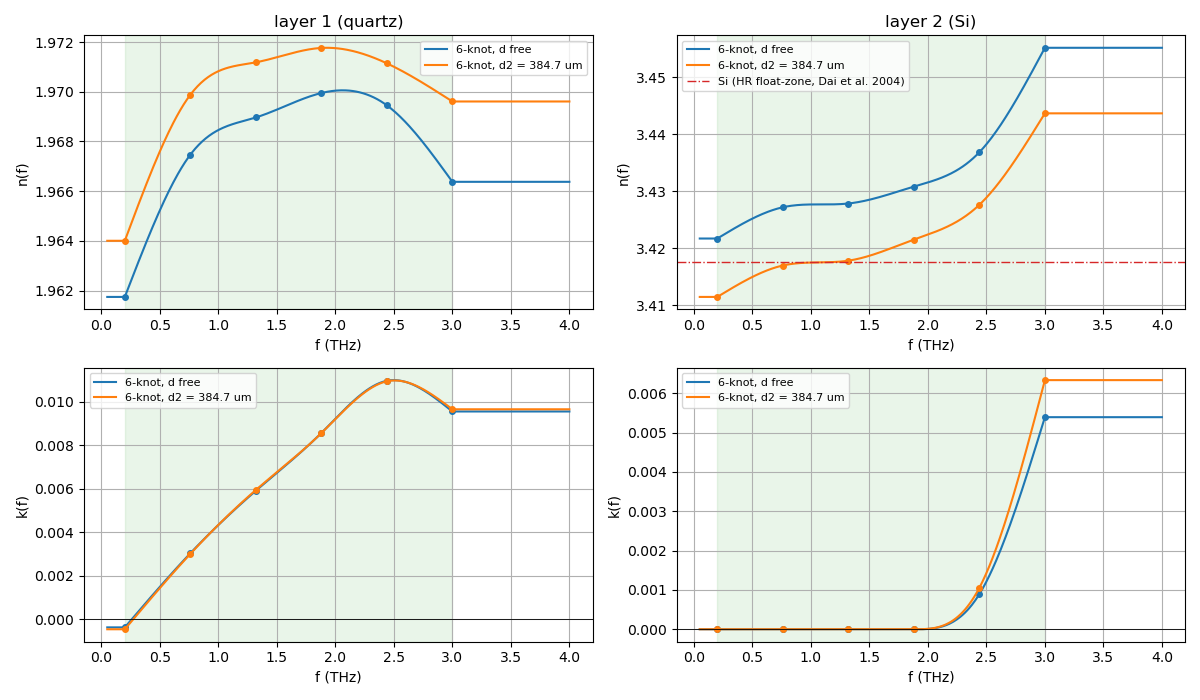

loss: d free 2.8544e-03   d2 pinned 2.8648e-03


In [42]:
RUN_PINNED_D2 = True
D2_PINNED = None           # metres; None -> use n*d of the free fit divided by the literature index N_SI_LIT
N_SI_LIT  = 3.4175

if RUN_PINNED_D2:
    st_free = model.state()
    if D2_PINNED is None:
        n_si_1thz = float(np.interp(1.0, f_knots, st_free['n'][1].numpy()))
        D2_PINNED = n_si_1thz * st_free['d'][1].item() / N_SI_LIT
    print(f"pinning d2 = {D2_PINNED*1e6:.2f} um")

    model_pin = copy.deepcopy(model_flat)              # stage-1 solution (flat n, k) as the starting point
    model_pin.load_state(model_pin.state())
    model_pin.d_init[1] = D2_PINNED
    model_pin.d_mask[1] = 0.0                          # d2 frozen, d1 still free
    model_pin.set_dispersion(True)

    traj_pin = fit(model_pin, n_iters=N_ITERS_DISP, lr=LR, print_step=5000, label='d2 pinned')
    model_pin.report()
    plot_pulses(model_pin, title=f'Stage 2 with d2 pinned at {D2_PINNED*1e6:.1f} um')
    plot_nk([model, model_pin], [f'{N_KNOTS}-knot, d free', f'{N_KNOTS}-knot, d2 = {D2_PINNED*1e6:.1f} um'])
    print(f"loss: d free {traj_disp['loss'][-1]:.4e}   d2 pinned {traj_pin['loss'][-1]:.4e}")

## 9. Alternative: everything free from the start (single stage)

Useful to check that the two-stage path did not trap the fit; in a well-conditioned case both end at the same
$n(f)$, $k(f)$. Compare the final losses.

In [43]:
RUN_SINGLE_STAGE = False

if RUN_SINGLE_STAGE:
    model_1s = DispersiveTwoLayerGrid(n_init, k_init, d_init)
    model_1s.set_dispersion(True); model_1s.set_thickness(FIT_THICKNESS)
    traj_1s = fit(model_1s, n_iters=N_ITERS_FLAT + N_ITERS_DISP, lr=LR, print_step=5000, label='single-stage')
    model_1s.report()
    plot_nk([model, model_1s], ['two-stage', 'single-stage'], true_coefs=true_coefs)
    print(f"final loss two-stage {traj_disp['loss'][-1]:.4e}   single-stage {traj_1s['loss'][-1]:.4e}")

## 10. Export $n(f)$, $k(f)$ tables and coefficients

The optical-path degeneracy of the original problem is still there: $n_j$ and $d_j$ trade against each other
(only $n_j d_j$ is tightly constrained by the pulse delay; the Fabry-Pérot echoes break the degeneracy weakly).
If you know a thickness from an independent measurement, set `FIT_THICKNESS = False` and put it in `d_init`.

In [44]:
f_out = np.arange(F_LO, F_HI + 1e-9, 0.01)
with torch.no_grad():
    n_out, k_out = model.nk(f_out)
    n_out, k_out = n_out.numpy(), k_out.numpy()

table = np.column_stack([f_out, n_out[0], k_out[0], n_out[1], k_out[1]])
np.savetxt('QuartzSi_nk_of_f_grid.txt', table, fmt='%.6e',
           header=f'f_THz  n_quartz  k_quartz  n_Si  k_Si   ({N_KNOTS}-knot {INTERP} interpolation, knots at '
                  + ', '.join(f'{f:.3f}' for f in f_knots) + ' THz)')

st = model.state()
np.savez('QuartzSi_grid_knots.npz', f_knots=f_knots, n_knots=st['n'].numpy(), k_knots=st['k'].numpy(), d=st['d'].numpy(),
         F_LO=F_LO, F_HI=F_HI, interp=INTERP)
print(table[::50])

[[ 2.00000000e-01  1.96174932e+00 -3.71979084e-04  3.42167878e+00
   9.11019740e-08]
 [ 7.00000000e-01  1.96705687e+00  2.68731010e-03  3.42683744e+00
   2.24752966e-07]
 [ 1.20000000e+00  1.96880627e+00  5.33617567e-03  3.42767310e+00
   1.55690941e-07]
 [ 1.70000000e+00  1.96967185e+00  7.65177840e-03  3.42963743e+00
   9.06511559e-07]
 [ 2.20000000e+00  1.96998417e+00  1.02417106e-02  3.43311429e+00
   1.64355355e-04]
 [ 2.70000000e+00  1.96824467e+00  1.06845535e-02  3.44411612e+00
   2.63675721e-03]]


## 10b. Knot values vs literature

Fitted knot values next to reference values (fill `LITERATURE` above with the data set that applies to layer 1).
For high-resistivity silicon the literature index is 3.4175 and flat to 1e-4 (Dai et al., JOSA B 21, 1379 (2004)).

In [45]:
st = model.state()
n1, k1, n2, k2 = st['n'][0].numpy(), st['k'][0].numpy(), st['n'][1].numpy(), st['k'][1].numpy()
print(f"{'f (THz)':>8} | {'n_quartz':>9} {'k_quartz':>9} | {'n_Si':>8} {'k_Si':>9} | {'n_Si-3.4175':>11}")
for q in range(N_KNOTS):
    print(f"{f_knots[q]:8.3f} | {n1[q]:9.4f} {k1[q]:9.5f} | {n2[q]:8.4f} {k2[q]:9.6f} | {n2[q]-3.4175:+11.4f}")
d1, d2 = st['d'][0].item(), st['d'][1].item()
print(f"\nthicknesses: d1 = {d1*1e6:.2f} um, d2 = {d2*1e6:.2f} um")
n1_1, n2_1 = np.interp(1.0, f_knots, n1), np.interp(1.0, f_knots, n2)
print(f"optical thickness n*d at 1 THz: quartz {n1_1*d1*1e6:.1f} um, Si {n2_1*d2*1e6:.1f} um  "
      f"(-> d_Si = {n2_1*d2*1e6/3.4175:.1f} um if n_Si = 3.4175)")

 f (THz) |  n_quartz  k_quartz |     n_Si      k_Si | n_Si-3.4175
   0.200 |    1.9617  -0.00037 |   3.4217  0.000000 |     +0.0042
   0.760 |    1.9675   0.00303 |   3.4272  0.000000 |     +0.0097
   1.320 |    1.9690   0.00591 |   3.4278  0.000000 |     +0.0103
   1.880 |    1.9699   0.00856 |   3.4308  0.000000 |     +0.0133
   2.440 |    1.9695   0.01096 |   3.4368  0.000893 |     +0.0193
   3.000 |    1.9664   0.00955 |   3.4551  0.005390 |     +0.0376

thicknesses: d1 = 992.85 um, d2 = 383.54 um
optical thickness n*d at 1 THz: quartz 1954.0 um, Si 1314.6 um  (-> d_Si = 384.7 um if n_Si = 3.4175)


## 11. Loss landscape in any two coefficients

Same idea as the original 3D landscapes, now over any pair of model quantities. Names:
`n1_q3` = 3rd knot (1-based) of n of layer 1, `k2_q1`, ..., `d1`, `d2`.
A landscape that is flat along a knot means the data do not constrain the index at that frequency.

In [46]:
def _get_set(model, name):
    '''Return (getter, setter) acting directly on the *init* tensors of `model` (raw are zero after load_state).'''
    if name.startswith('d'):
        j = int(name[1]) - 1
        return (lambda: model.d_init[j].item()), (lambda v: model.d_init.__setitem__(j, v))
    q, kname = name.split('_')                       # e.g. 'n1', 'q3'
    j = int(q[1]) - 1; i = int(kname[1:]) - 1
    tgt = model.n_init if q[0] == 'n' else model.k_init
    return (lambda: tgt[j, i].item()), (lambda v: tgt.__setitem__((j, i), v))


def loss_landscape(model, xname, yname, n_pts=60, span_x=0.02, span_y=0.02, absolute=False):
    '''
    Loss over a grid around the model's current solution.
    span_* : half-width of the scan. If absolute=False it is relative to the current value (as in the original
             notebook, e.g. 0.5 = +-50%); if absolute=True it is an absolute half-width (needed for coefficients
             that are ~0, such as a, b, c).
    '''
    m = copy.deepcopy(model)
    m.load_state(m.state())
    gx, sx = _get_set(m, xname); gy, sy = _get_set(m, yname)
    x0, y0 = gx(), gy()
    xs = x0 + np.linspace(-1, 1, n_pts) * (span_x if absolute else abs(x0) * span_x)
    ys = y0 + np.linspace(-1, 1, n_pts) * (span_y if absolute else abs(y0) * span_y)
    y_meas = torch.as_tensor(true_x_exp)
    Z = np.zeros((n_pts, n_pts))
    with torch.no_grad():
        for a, xv in enumerate(tqdm(xs, leave=False)):
            sx(float(xv))
            for b, yv in enumerate(ys):
                sy(float(yv))
                _, y = m.forward(x_exp)
                Z[b, a] = total_loss(y, y_meas, m).item()
    X, Y = np.meshgrid(xs, ys)
    return X, Y, Z, (x0, y0)


def plot_landscape(X, Y, Z, center, xname, yname, traj=None):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    cf = ax[0].contourf(X, Y, np.log10(Z), 30, cmap='viridis'); plt.colorbar(cf, ax=ax[0], label='log10 loss')
    ax[0].plot(*center, 'r*', ms=10, label='fit')
    ax[0].set_xlabel(xname); ax[0].set_ylabel(yname); ax[0].legend()
    ax[1].remove(); ax3 = fig.add_subplot(1, 2, 2, projection='3d')
    ax3.plot_surface(X, Y, Z, cmap='terrain', alpha=0.7, linewidth=0, antialiased=True)
    ax3.set_xlabel(xname); ax3.set_ylabel(yname); ax3.set_zlabel('loss')
    plt.tight_layout(); plt.show()

  0%|          | 0/40 [00:00<?, ?it/s]

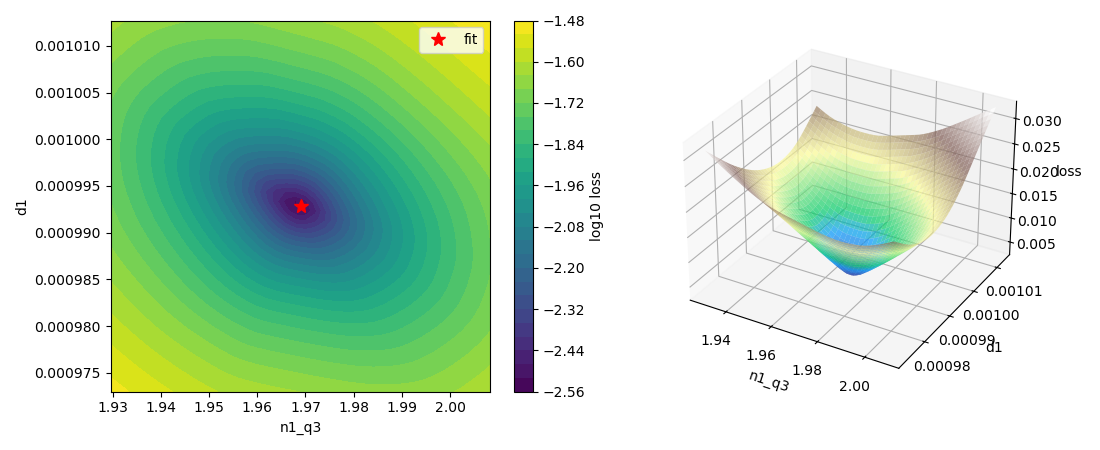

  0%|          | 0/40 [00:00<?, ?it/s]

/var/folders/rv/bq00xs9s6419dybn8n4sccxw0000gn/T/ipykernel_65268/1364743474.py:39: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))


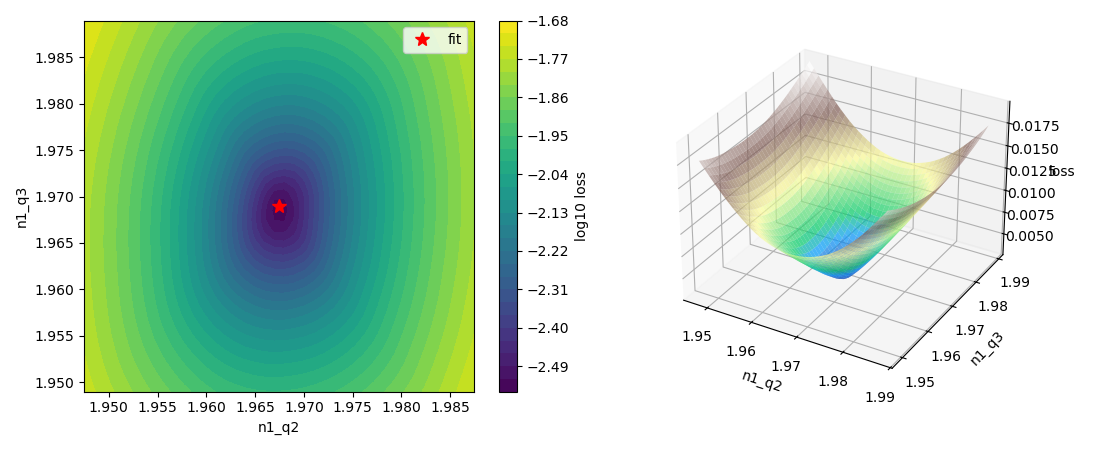

  0%|          | 0/40 [00:00<?, ?it/s]

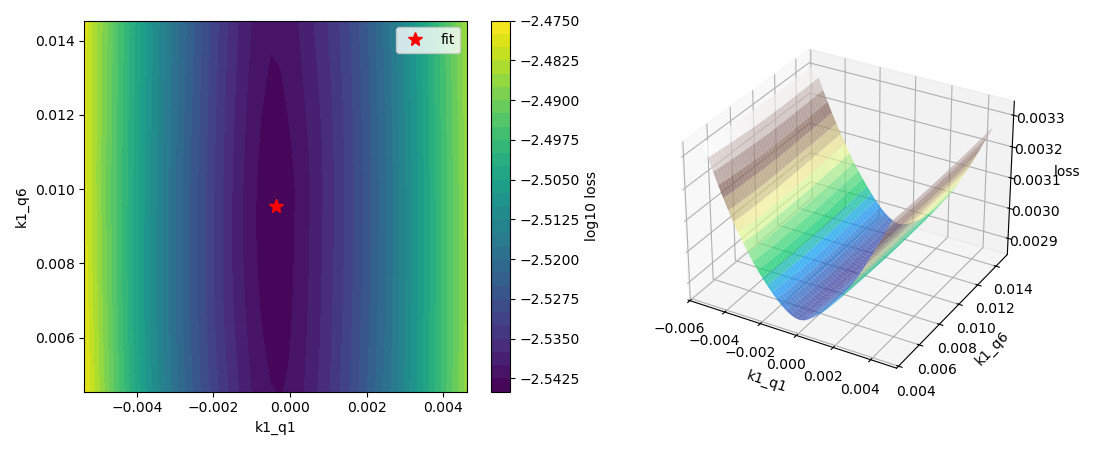

In [47]:
RUN_LANDSCAPES = True
if RUN_LANDSCAPES:
    # n knot at ~1.3 THz vs thickness: the optical-path valley (relative +-2 %)
    X_, Y_, Z_, c_ = loss_landscape(model, 'n1_q3', 'd1', n_pts=40, span_x=0.02, span_y=0.02)
    plot_landscape(X_, Y_, Z_, c_, 'n1_q3', 'd1')

    # two neighbouring n knots of quartz: how independent are they? (absolute +-0.02)
    X_, Y_, Z_, c_ = loss_landscape(model, 'n1_q2', 'n1_q3', n_pts=40, span_x=0.02, span_y=0.02, absolute=True)
    plot_landscape(X_, Y_, Z_, c_, 'n1_q2', 'n1_q3')

    # k knots of quartz at the band edges (absolute +-0.005)
    X_, Y_, Z_, c_ = loss_landscape(model, 'k1_q1', 'k1_q6', n_pts=40, span_x=0.005, span_y=0.005, absolute=True)
    plot_landscape(X_, Y_, Z_, c_, 'k1_q1', 'k1_q6')

## Notes / knobs

* **Knots** `N_KNOTS`, band `F_LO, F_HI`, interpolation `INTERP` ('linear' gives piecewise-linear curves and is the
  most assumption-free; 'cubic' gives smooth curves but a natural spline can overshoot between knots).
  Non-uniform knots: replace `f_knots = np.linspace(...)` by any sorted array.
* **Scales** `n_scale`, `k_scale`: absolute step scales for the knots (Adam moves about `lr x scale` per
  iteration). Defaults 0.05 and 0.005.
* **Regularisation**: none by construction. With 6 free knots the fit can trade index wiggles against thickness
  (the `n1_q3`-`d1` landscape shows the valley); if the knots come out noisy, either fix `d` (`FIT_THICKNESS=False`
  with a mechanically measured thickness) or add a smoothness penalty, e.g. `lam * ((n[:,1:]-n[:,:-1])**2).sum()`
  on the knot values, in `total_loss`.
* **Positivity of k**: soft via `K_POS_WEIGHT` as in the polynomial notebook.
* Output files: `QuartzSi_nk_of_f_grid.txt`, `QuartzSi_grid_knots.npz`.